In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# 1. Column names, data types, and non-empty counts
df.info()

# 2. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# 3. Missing values
print("\nMissing values per column:")
print(df.isna().sum())

# 4. Basic statistics for the number columns
df[["tenure", "MonthlyCharges"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,tenure,MonthlyCharges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


In [3]:
# Fix TotalCharges: it is text, convert to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges found:", df["TotalCharges"].isna().sum())
print(df[df["TotalCharges"].isna()][["customerID", "tenure"]].head())

# These customers have tenure 0 (brand new, nothing billed yet), so fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# SeniorCitizen is 0/1, make it Yes/No like the other columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Make inconsistent labels consistent
for c in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})

# Numeric churn column for calculations
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# Outlier check (IQR method)
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"Outliers in {c}: {n}")

Blank TotalCharges found: 11
      customerID  tenure
488   4472-LVYGI       0
753   3115-CZMZD       0
936   5709-LVOEQ       0
1082  4367-NUYAO       0
1340  1371-DWPAZ       0
Outliers in tenure: 0
Outliers in MonthlyCharges: 0
Outliers in TotalCharges: 0


In [4]:
print("Overall churn rate: %.2f%%" % (df["ChurnFlag"].mean()*100))

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    print(f"\nChurn % by {col}")
    print((df.groupby(col)["ChurnFlag"].mean()*100).round(2).sort_values(ascending=False))

df["TenureGroup"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
print("\nChurn % by tenure group (months)")
print((df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean()*100).round(2))

print("\nAverages for churned vs stayed")
print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2))

print("\nCorrelation")
print(df[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]].corr().round(3))

Overall churn rate: 26.54%

Churn % by Contract
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64

Churn % by InternetService
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: ChurnFlag, dtype: float64

Churn % by PaymentMethod
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: ChurnFlag, dtype: float64

Churn % by TechSupport
TechSupport
No     31.19
Yes    15.17
Name: ChurnFlag, dtype: float64

Churn % by SeniorCitizen
SeniorCitizen
Yes    41.68
No     23.61
Name: ChurnFlag, dtype: float64

Churn % by tenure group (months)
TenureGroup
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: ChurnFlag, dtype: float64

Averages for churned vs stayed
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       25

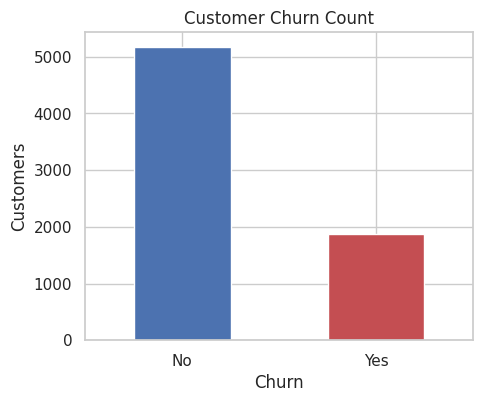

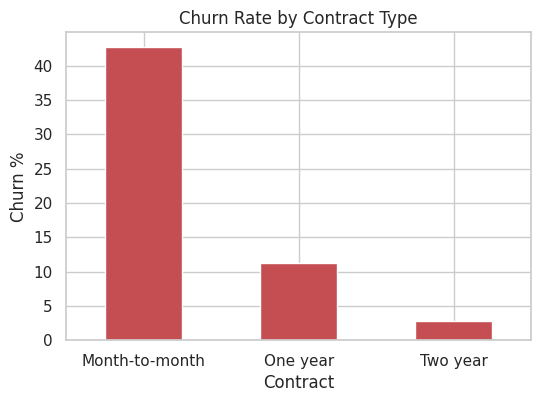

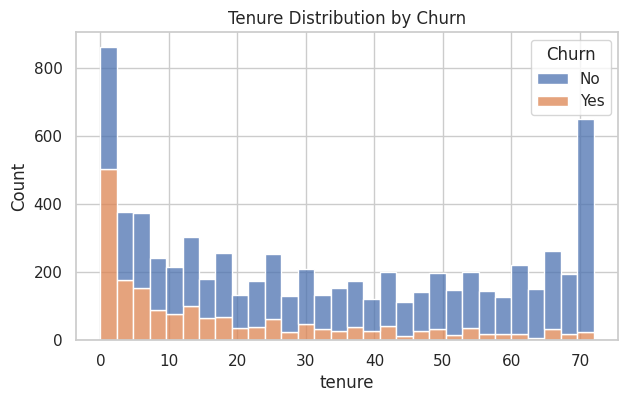

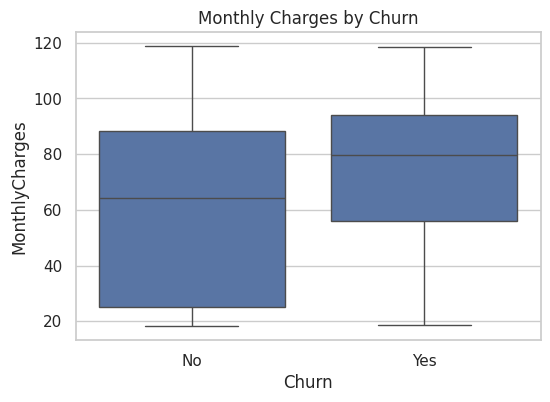

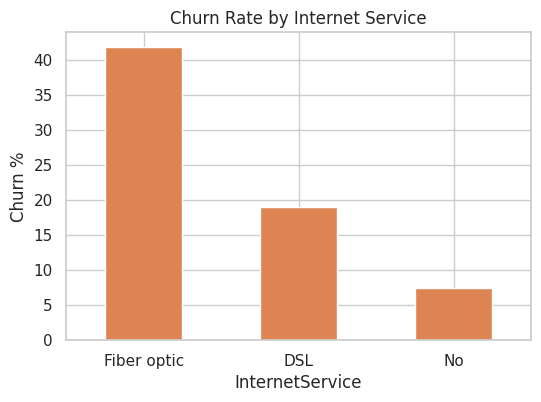

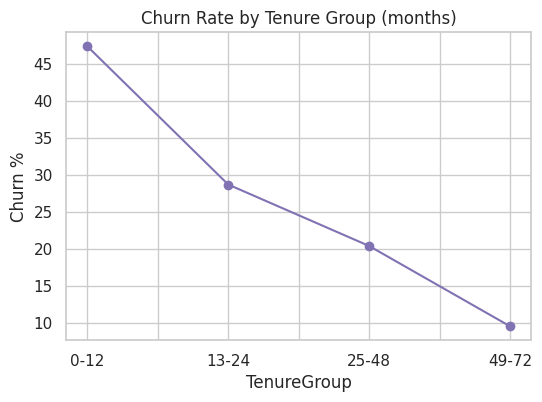

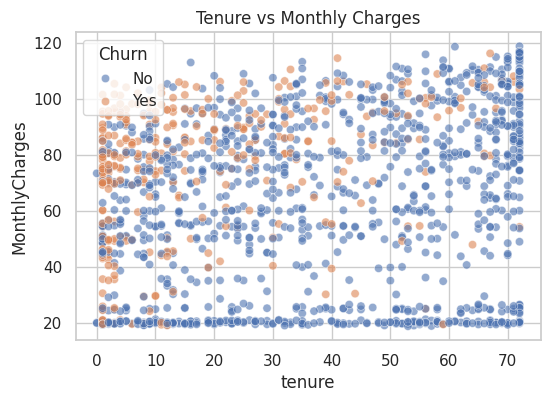

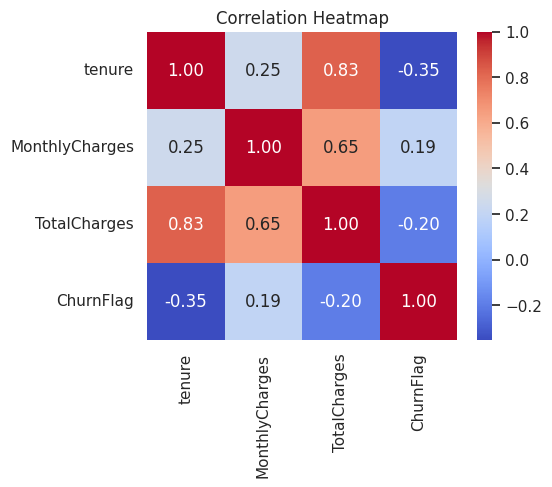

In [6]:
sns.set_theme(style="whitegrid")

# 1. Churn count
plt.figure(figsize=(5,4))
df["Churn"].value_counts().plot.bar(color=["#4c72b0", "#c44e52"])
plt.title("Customer Churn Count"); plt.ylabel("Customers"); plt.xticks(rotation=0)
plt.show()

# 2. Churn by contract
plt.figure(figsize=(6,4))
(df.groupby("Contract")["ChurnFlag"].mean()*100).sort_values(ascending=False).plot.bar(color="#c44e52")
plt.title("Churn Rate by Contract Type"); plt.ylabel("Churn %"); plt.xticks(rotation=0)
plt.show()

# 3. Tenure histogram
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Tenure Distribution by Churn")
plt.show()

# 4. Box plot
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn")
plt.show()

# 5. Churn by internet service
plt.figure(figsize=(6,4))
(df.groupby("InternetService")["ChurnFlag"].mean()*100).sort_values(ascending=False).plot.bar(color="#dd8452")
plt.title("Churn Rate by Internet Service"); plt.ylabel("Churn %"); plt.xticks(rotation=0)
plt.show()

# 6. Line chart: churn by tenure group
plt.figure(figsize=(6,4))
(df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean()*100).plot(marker="o", color="#8172b3")
plt.title("Churn Rate by Tenure Group (months)"); plt.ylabel("Churn %")
plt.show()

# 7. Scatter plot
plt.figure(figsize=(6,4))
sns.scatterplot(data=df.sample(1500, random_state=1), x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.6)
plt.title("Tenure vs Monthly Charges")
plt.show()

# 8. Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()